# Preparación de variables para la segmentación de proveedores
**Proyecto BI – Purchasing**

**Historia de usuario 3.1:** como equipo, queremos preparar las variables para obtener una segmentación de proveedores confiable.

| Task | Contenido | Sección |
|---|---|---|
| 3.1.1 | Resumen estadístico de monto total comprado, cantidad de órdenes y precio promedio | 2 |
| 3.1.2 | Histogramas y análisis univariado | 3 |
| 3.1.3 | Selección y justificación de las variables del clustering (con base en el EDA de Miguel) | 4 |
| 3.1.4 | Preparación de los datos finales y `StandardScaler` | 5 |

Las secciones son secuenciales: la 3.1.1 describe las variables clave, la 3.1.2 amplía el análisis a todas las variables numéricas, la 3.1.3 elige las variables del modelo con esa evidencia y la correlación del EDA, y la 3.1.4 transforma y escala solo las variables elegidas.

**Entrada:** `data/processed/purchasing_consolidated.csv` (generado por `src/consolidate_data.py`).
**Salida:** `data/processed/purchasing_clustering_final.csv` y `data/processed/scaler_clustering.joblib`.

## 1. Configuración y carga de datos

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings; warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.2f}".format)

ROOT = Path("..") if Path("../data").exists() else Path(".")
PROC = ROOT / "data/processed"

consol = pd.read_csv(PROC / "purchasing_consolidated.csv")

# Misma población que el EDA: proveedores con al menos una orden de compra
datos = consol.dropna(subset=["NumeroOrdenes", "ValorTotalOrdenes"]).copy()

print(f"Proveedores en el consolidado : {len(consol)}")
print(f"Excluidos (sin órdenes)       : {len(consol) - len(datos)}")
print(f"Proveedores analizados        : {len(datos)}")

Proveedores en el consolidado : 106
Excluidos (sin órdenes)       : 18
Proveedores analizados        : 88


## 2. Task 3.1.1 – Resumen estadístico de las variables de compra

### 2.1 Variables analizadas y su origen

Las tres variables salen del consolidado por proveedor, generado por `src/consolidate_data.py`.

| Concepto de la tarea | Columna | Cómo se calcula |
|---|---|---|
| Monto total comprado | `ValorTotalOrdenes` | Suma de `TotalDue` de las órdenes del proveedor (`PurchaseOrderHeader`). |
| Cantidad de órdenes | `NumeroOrdenes` | Cantidad de `PurchaseOrderID` distintos por proveedor. |
| Precio promedio | `PrecioEstandarPromedio` | Promedio de `StandardPrice` de los productos que ofrece el proveedor (`ProductVendor`). |

Como apoyo se incluye también `GastoPromedioOrden` (promedio de `TotalDue` por orden). **No es un precio unitario**, es el gasto medio por orden, y se muestra aparte para no confundirlo con el precio promedio.

> **Nota:** `PrecioEstandarPromedio` es el precio estándar del catálogo de `ProductVendor`, no el precio de lo realmente comprado. Si el equipo define "precio promedio" como el precio unitario real de las compras (`UnitPrice` en `PurchaseOrderDetail`), esa columna debe agregarse en `consolidate_data.py`.

In [2]:
VARS = {
    "ValorTotalOrdenes": "Monto total comprado",
    "NumeroOrdenes": "Cantidad de órdenes",
    "PrecioEstandarPromedio": "Precio promedio (estándar)",
}
APOYO = {"GastoPromedioOrden": "Gasto promedio por orden (apoyo)"}

faltan = [c for c in [*VARS, *APOYO] if c not in consol.columns]
assert not faltan, f"Columnas ausentes en el consolidado: {faltan}"

print("Nulos por variable en la población analizada:")
display(datos[[*VARS, *APOYO]].isna().sum().rename("Nulos").to_frame())

Nulos por variable en la población analizada:


,Nulos
ValorTotalOrdenes,0
NumeroOrdenes,0
PrecioEstandarPromedio,0
GastoPromedioOrden,0


### 2.2 Tabla de resumen estadístico

Se reportan medidas de tendencia central, posición, dispersión y forma. El **coeficiente de variación** (desviación estándar / media) permite comparar la dispersión de variables con unidades distintas, y la **asimetría** indica el sentido del sesgo (positiva = cola larga a la derecha).

In [3]:
def resumen(df, columnas):
    filas = {}
    for col, etiqueta in columnas.items():
        s = df[col].dropna()
        q1, q3 = s.quantile([.25, .75])
        filas[etiqueta] = {
            "N": s.count(),
            "Suma": s.sum(),
            "Media": s.mean(),
            "Mediana": s.median(),
            "Moda": s.mode().iloc[0] if not s.mode().empty else np.nan,
            "Mín": s.min(),
            "P5": s.quantile(.05),
            "Q1 (P25)": q1,
            "Q3 (P75)": q3,
            "P95": s.quantile(.95),
            "Máx": s.max(),
            "Rango": s.max() - s.min(),
            "IQR": q3 - q1,
            "Varianza": s.var(),
            "Desv. estándar": s.std(),
            "Coef. variación (%)": s.std() / s.mean() * 100,
            "Asimetría": s.skew(),
            "Curtosis": s.kurt(),
        }
    return pd.DataFrame(filas)

tabla_principal = resumen(datos, VARS)
display(tabla_principal)

,Monto total comprado,Cantidad de órdenes,Precio promedio (estándar)
N,88.00,88.00,88.00
Suma,"70,486,431.69","4,019.00","2,653.02"
Media,"800,982.18",45.67,30.15
Mediana,"102,009.78",51.00,35.47
Moda,"1,952,375.30",51.00,37.99
Mín,17.00,1.00,0.20
P5,"5,167.89",1.35,3.63
Q1 (P25),"25,603.70",50.00,15.49
Q3 (P75),"1,491,743.72",51.00,40.53
P95,"2,742,056.42",51.00,51.98


In [4]:
print("Variable de apoyo (no es precio unitario):")
display(resumen(datos, APOYO))

Variable de apoyo (no es precio unitario):


,Gasto promedio por orden (apoyo)
N,88.00
Suma,"2,777,344.94"
Media,"31,560.74"
Mediana,"6,335.02"
Moda,"38,281.87"
Mín,17.00
P5,110.03
Q1 (P25),520.18
Q3 (P75),"31,978.38"
P95,"66,910.04"


### 2.3 Distribución de las tres variables

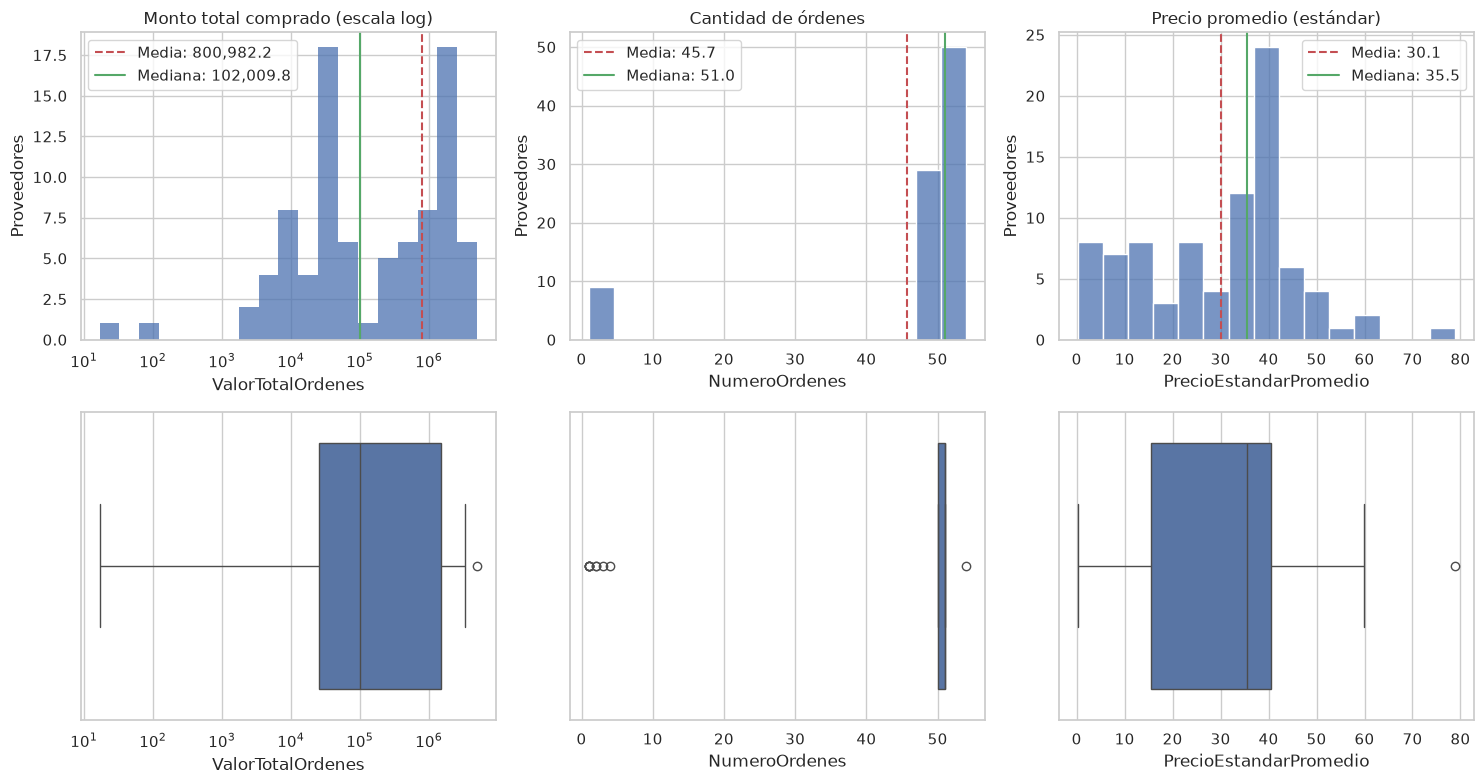

In [5]:
LOG = {"ValorTotalOrdenes"}   # muy asimétrica: se grafica en escala logarítmica

fig, axes = plt.subplots(2, len(VARS), figsize=(5 * len(VARS), 8))
for j, (col, etiqueta) in enumerate(VARS.items()):
    s = datos[col].dropna()
    bins = np.logspace(np.log10(s[s > 0].min()), np.log10(s.max()), 20) if col in LOG else 15

    sns.histplot(s, bins=bins, ax=axes[0, j], color="#4C72B0")
    axes[0, j].axvline(s.mean(), color="#C44E52", ls="--", label=f"Media: {s.mean():,.1f}")
    axes[0, j].axvline(s.median(), color="#55A868", ls="-", label=f"Mediana: {s.median():,.1f}")
    axes[0, j].set_title(etiqueta + (" (escala log)" if col in LOG else ""))
    axes[0, j].set_xlabel(col); axes[0, j].set_ylabel("Proveedores"); axes[0, j].legend()

    sns.boxplot(x=s, ax=axes[1, j], color="#4C72B0")
    axes[1, j].set_xlabel(col)
    if col in LOG:
        axes[0, j].set_xscale("log"); axes[1, j].set_xscale("log")

plt.tight_layout(); plt.show()

### 2.4 Lectura de los resultados

In [6]:
# Interpretación generada a partir de los datos calculados arriba
def lectura(col, etiqueta):
    t = tabla_principal[etiqueta]
    sesgo = ("sesgo a la derecha (pocos proveedores con valores muy altos)" if t["Asimetría"] > 0.5
             else "sesgo a la izquierda (pocos proveedores con valores muy bajos)" if t["Asimetría"] < -0.5
             else "distribución aproximadamente simétrica")
    disp = "alta" if t["Coef. variación (%)"] > 100 else "moderada" if t["Coef. variación (%)"] > 50 else "baja"
    return (f"- {etiqueta}: media {t['Media']:,.2f} vs mediana {t['Mediana']:,.2f}; "
            f"rango [{t['Mín']:,.2f} – {t['Máx']:,.2f}]; "
            f"dispersión {disp} (CV = {t['Coef. variación (%)']:.1f} %); {sesgo}.")

print(f"Sobre {len(datos)} proveedores con órdenes de compra:\n")
for col, etiqueta in VARS.items():
    print(lectura(col, etiqueta))

top10 = datos.nlargest(10, "ValorTotalOrdenes")["ValorTotalOrdenes"].sum() / datos["ValorTotalOrdenes"].sum() * 100
print(f"\nLos 10 proveedores con mayor monto concentran el {top10:.1f} % del monto total comprado.")

Sobre 88 proveedores con órdenes de compra:

- Monto total comprado: media 800,982.18 vs mediana 102,009.78; rango [17.00 – 5,034,266.74]; dispersión alta (CV = 133.7 %); sesgo a la derecha (pocos proveedores con valores muy altos).
- Cantidad de órdenes: media 45.67 vs mediana 51.00; rango [1.00 – 54.00]; dispersión baja (CV = 32.7 %); sesgo a la izquierda (pocos proveedores con valores muy bajos).
- Precio promedio (estándar): media 30.15 vs mediana 35.47; rango [0.20 – 78.89]; dispersión moderada (CV = 53.0 %); distribución aproximadamente simétrica.

Los 10 proveedores con mayor monto concentran el 42.6 % del monto total comprado.


**Nota:** la asimetría y el coeficiente de variación de estas variables determinan el tratamiento previo al clustering. Las secciones 3 a 5 amplían el análisis univariado, eligen las variables del modelo y aplican la transformación y el escalado.

## 3. Task 3.1.2 – Histogramas y análisis univariado

Se analiza cada variable numérica del consolidado por separado: forma de la distribución, tendencia central, dispersión y valores atípicos. Los identificadores (`VendorID`) y las fechas no se analizan.

In [7]:
NUMERICAS = [
    "NumeroOrdenes", "ValorTotalOrdenes", "GastoPromedioOrden",
    "UnidadesPedidas", "ProductosComprados", "ValorLineas",
    "ProductosOfrecidos", "TiempoEntregaPromedio", "PrecioEstandarPromedio",
]
faltan = [c for c in NUMERICAS if c not in datos.columns]
assert not faltan, f"Columnas ausentes en el consolidado: {faltan}"

def forma(asim):
    if asim > 1:    return "muy asimétrica a la derecha"
    if asim > 0.5:  return "asimetría moderada a la derecha"
    if asim < -1:   return "muy asimétrica a la izquierda"
    if asim < -0.5: return "asimetría moderada a la izquierda"
    return "aproximadamente simétrica"

def univariado(df, columnas):
    filas = {}
    for c in columnas:
        s = df[c].dropna()
        q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
        n_out = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
        filas[c] = {
            "N": s.count(), "Nulos": df[c].isna().sum(),
            "Media": s.mean(), "Mediana": s.median(), "Desv. est.": s.std(),
            "Mín": s.min(), "Máx": s.max(),
            "CV (%)": s.std() / s.mean() * 100,
            "Asimetría": s.skew(), "Curtosis": s.kurt(),
            "Outliers IQR": n_out, "% outliers": n_out / len(s) * 100,
            "Forma": forma(s.skew()),
        }
    return pd.DataFrame(filas).T

tabla_uni = univariado(datos, NUMERICAS)
tabla_uni

,N,Nulos,Media,Mediana,Desv. est.,Mín,Máx,CV (%),Asimetría,Curtosis,Outliers IQR,% outliers,Forma
NumeroOrdenes,88,0,45.67,51.00,14.91,1.00,54.00,32.66,-2.67,5.25,10,11.36,muy asimétrica a la izquierda
ValorTotalOrdenes,88,0,"800,982.18","102,009.78","1,071,243.46",17.00,"5,034,266.74",133.74,1.43,1.81,1,1.14,muy asimétrica a la derecha
GastoPromedioOrden,88,0,"31,560.74","6,335.02","84,775.73",17.00,"609,422.00",268.61,5.35,31.08,4,4.55,muy asimétrica a la derecha
UnidadesPedidas,88,0,"26,689.22","17,300.00","30,393.44",3.00,"125,000.00",113.88,1.05,0.46,0,0.00,muy asimétrica a la derecha
ProductosComprados,88,0,5.30,2.00,6.49,1.00,30.00,122.59,1.86,2.85,6,6.82,muy asimétrica a la derecha
ValorLineas,88,0,"724,910.62","92,316.55","969,506.55",15.00,"4,555,897.50",133.74,1.43,1.81,1,1.14,muy asimétrica a la derecha
ProductosOfrecidos,88,0,5.31,2.00,6.46,1.00,30.00,121.80,1.86,2.90,6,6.82,muy asimétrica a la derecha
TiempoEntregaPromedio,88,0,18.33,17.00,6.87,1.50,55.00,37.46,3.20,13.45,8,9.09,muy asimétrica a la derecha
PrecioEstandarPromedio,88,0,30.15,35.47,15.99,0.20,78.89,53.03,-0.05,-0.22,1,1.14,aproximadamente simétrica


### 3.1 Histogramas de las variables numéricas
La línea roja es la media y la verde la mediana; cuando están muy separadas, la variable es asimétrica.

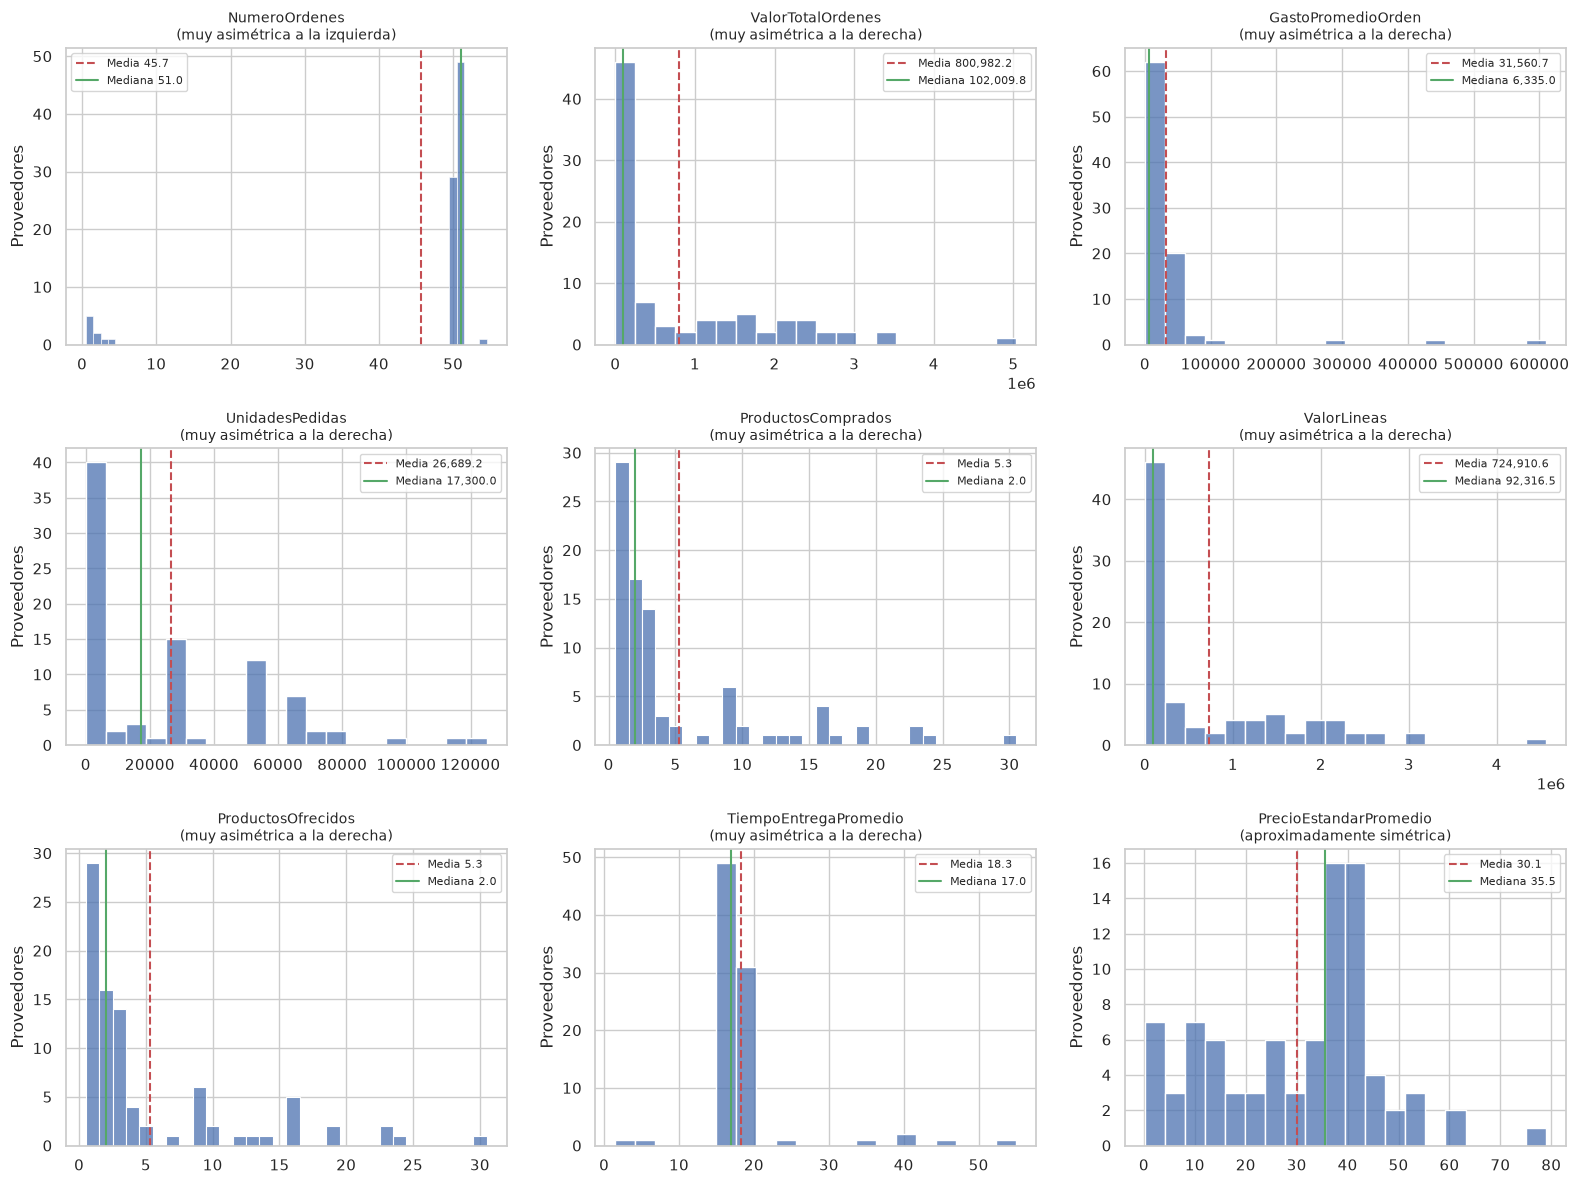

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, c in zip(axes.ravel(), NUMERICAS):
    s = datos[c].dropna()
    discreta = s.nunique() <= 20 and np.allclose(s, s.round())
    sns.histplot(s, ax=ax, color="#4C72B0", discrete=discreta, bins="auto" if discreta else 20)
    ax.axvline(s.mean(), color="#C44E52", ls="--", label=f"Media {s.mean():,.1f}")
    ax.axvline(s.median(), color="#55A868", ls="-", label=f"Mediana {s.median():,.1f}")
    ax.set_title(f"{c}\n({forma(s.skew())})", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("Proveedores"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3.2 Variables categóricas
`CreditRating` y las banderas del proveedor no se grafican como histograma, sino como conteos.

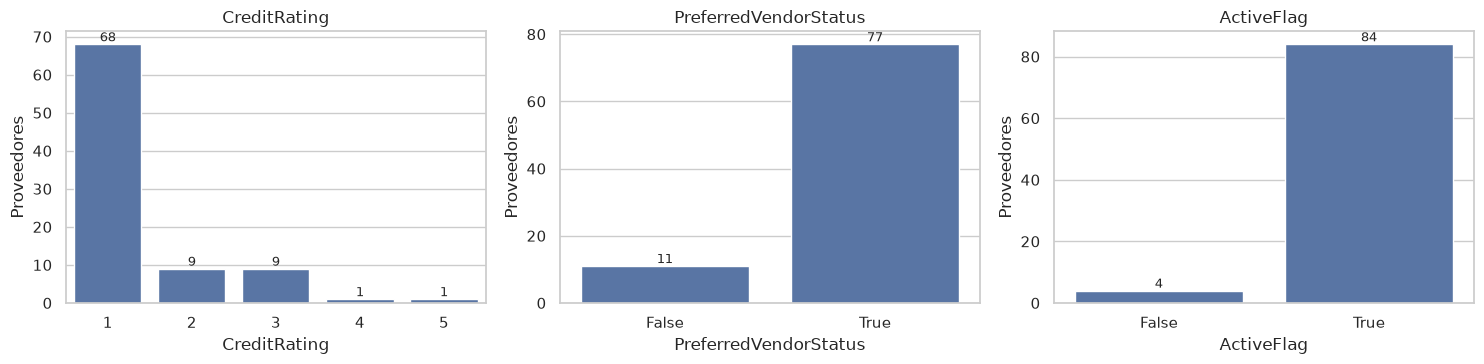

In [9]:
cats = [c for c in ["CreditRating", "PreferredVendorStatus", "ActiveFlag"] if c in datos.columns]
fig, axes = plt.subplots(1, len(cats), figsize=(5 * len(cats), 3.8))
for ax, c in zip(np.atleast_1d(axes), cats):
    sns.countplot(x=datos[c], ax=ax, color="#4C72B0")
    ax.set_title(c); ax.set_ylabel("Proveedores")
    for p in ax.patches:
        ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

### 3.3 Concentración de `NumeroOrdenes`
El EDA advierte que esta variable casi no varía en la mayoría de los proveedores. Se cuantifica aquí porque condiciona la interpretación del clustering.

In [10]:
no = datos["NumeroOrdenes"]
q1, q3 = no.quantile([.25, .75]); iqr = q3 - q1
bajo, alto = q1 - 1.5 * iqr, q3 + 1.5 * iqr
moda = no.mode().iloc[0]

pct_moda = (no == moda).mean() * 100
pct_iqr = ((no >= q1) & (no <= q3)).mean() * 100
atipicos = datos.loc[(no < bajo) | (no > alto), ["VendorID", "NombreProveedor", "NumeroOrdenes", "ValorTotalOrdenes"]]

print(f"Moda: {moda:.0f} órdenes ({pct_moda:.1f} % de los proveedores)")
print(f"Rango intercuartílico: [{q1:.0f}, {q3:.0f}] contiene al {pct_iqr:.1f} % de los proveedores")
print(f"Atípicos (fuera de [{bajo:.1f}, {alto:.1f}]): {len(atipicos)} proveedores ({len(atipicos)/len(no)*100:.1f} %)\n")
atipicos.sort_values("NumeroOrdenes")

Moda: 51 órdenes (55.7 % de los proveedores)
Rango intercuartílico: [50, 51] contiene al 88.6 % de los proveedores
Atípicos (fuera de [48.5, 52.5]): 10 proveedores (11.4 %)



,VendorID,NombreProveedor,NumeroOrdenes,ValorTotalOrdenes
13,1518,International Trek Center,1.00,"24,070.75"
14,1520,G & K Bicycle Corp.,1.00,"5,036.15"
92,1676,Team Athletic Co.,1.00,"436,401.90"
51,1594,Fitness Association,1.00,"609,422.00"
105,1700,garfield,1.00,17.00
41,1574,Jeff's Sporting Goods,2.00,"42,658.00"
27,1546,Green Lake Bike Company,2.00,"76,348.25"
104,1699,Distribuidora Ejemplo S.A.,3.00,83.10
72,1636,Integrated Sport Products,4.00,"1,186,835.76"
0,1492,Australia Bike Retailer,54.00,"32,058.99"


### 3.4 Efecto de la transformación logarítmica
Para las variables positivas y asimétricas se compara la asimetría antes y después de aplicar `log1p`. Esta evidencia respalda la decisión de la sección 5.

In [11]:
comp = pd.DataFrame({
    "Asimetría original": datos[NUMERICAS].skew(),
    "Asimetría con log1p": np.log1p(datos[NUMERICAS].clip(lower=0)).skew(),
})
comp["Mejora (|asim.| baja)"] = comp["Asimetría con log1p"].abs() < comp["Asimetría original"].abs()
comp

,Asimetría original,Asimetría con log1p,Mejora (|asim.| baja)
NumeroOrdenes,-2.67,-2.73,False
ValorTotalOrdenes,1.43,-0.69,True
GastoPromedioOrden,5.35,-0.14,True
UnidadesPedidas,1.05,-0.61,True
ProductosComprados,1.86,0.89,True
ValorLineas,1.43,-0.78,True
ProductosOfrecidos,1.86,0.87,True
TiempoEntregaPromedio,3.20,-1.72,True
PrecioEstandarPromedio,-0.05,-1.49,False


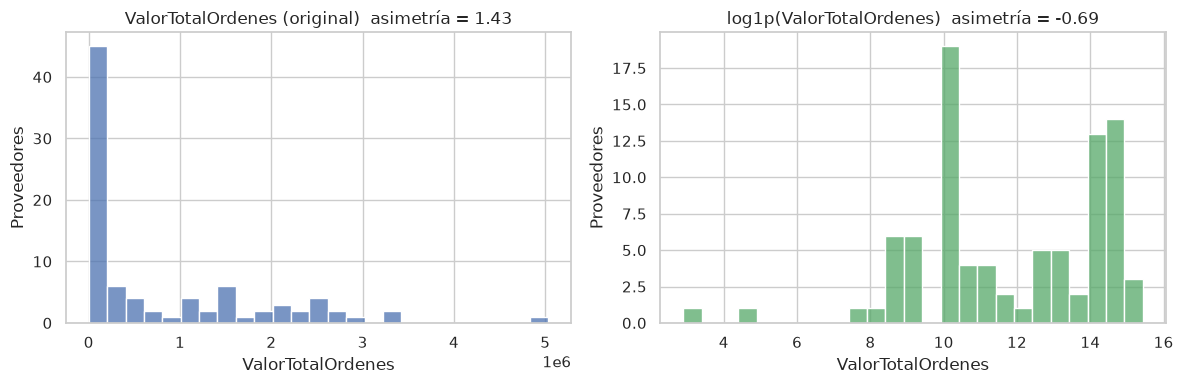

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(datos["ValorTotalOrdenes"], bins=25, ax=axes[0], color="#4C72B0")
axes[0].set_title(f"ValorTotalOrdenes (original)  asimetría = {datos['ValorTotalOrdenes'].skew():.2f}")
sns.histplot(np.log1p(datos["ValorTotalOrdenes"]), bins=25, ax=axes[1], color="#55A868")
axes[1].set_title(f"log1p(ValorTotalOrdenes)  asimetría = {np.log1p(datos['ValorTotalOrdenes']).skew():.2f}")
for ax in axes: ax.set_ylabel("Proveedores")
plt.tight_layout(); plt.show()

### 3.5 Documentación del análisis univariado
Texto generado a partir de los valores calculados arriba.

In [13]:
print(f"ANÁLISIS UNIVARIADO – {len(datos)} proveedores con órdenes de compra\n")
for c in NUMERICAS:
    t = tabla_uni.loc[c]
    disp = "alta" if t["CV (%)"] > 100 else "moderada" if t["CV (%)"] > 50 else "baja"
    print(f"• {c}: {t['Forma']}. Media {t['Media']:,.2f} vs mediana {t['Mediana']:,.2f}; "
          f"rango [{t['Mín']:,.2f} – {t['Máx']:,.2f}]; dispersión {disp} (CV {t['CV (%)']:.0f} %); "
          f"{int(t['Outliers IQR'])} atípicos ({t['% outliers']:.1f} %).")

ANÁLISIS UNIVARIADO – 88 proveedores con órdenes de compra

• NumeroOrdenes: muy asimétrica a la izquierda. Media 45.67 vs mediana 51.00; rango [1.00 – 54.00]; dispersión baja (CV 33 %); 10 atípicos (11.4 %).
• ValorTotalOrdenes: muy asimétrica a la derecha. Media 800,982.18 vs mediana 102,009.78; rango [17.00 – 5,034,266.74]; dispersión alta (CV 134 %); 1 atípicos (1.1 %).
• GastoPromedioOrden: muy asimétrica a la derecha. Media 31,560.74 vs mediana 6,335.02; rango [17.00 – 609,422.00]; dispersión alta (CV 269 %); 4 atípicos (4.5 %).
• UnidadesPedidas: muy asimétrica a la derecha. Media 26,689.22 vs mediana 17,300.00; rango [3.00 – 125,000.00]; dispersión alta (CV 114 %); 0 atípicos (0.0 %).
• ProductosComprados: muy asimétrica a la derecha. Media 5.30 vs mediana 2.00; rango [1.00 – 30.00]; dispersión alta (CV 123 %); 6 atípicos (6.8 %).
• ValorLineas: muy asimétrica a la derecha. Media 724,910.62 vs mediana 92,316.55; rango [15.00 – 4,555,897.50]; dispersión alta (CV 134 %); 1 atípic

## 4. Task 3.1.3 – Selección y justificación de variables

La selección parte de las recomendaciones del EDA de Miguel (`02_eda_miguel_parte1.ipynb`) y se contrasta con los datos de este notebook. Los criterios son:

1. **Alcance del sprint:** variables que describen el comportamiento de compra (monto y órdenes).
2. **No redundancia:** no incluir variables prácticamente idénticas o derivadas de otras ya elegidas, porque duplican su peso en las distancias de K-Means.
3. **Aporte de información:** que la variable tenga variación suficiente entre proveedores.
4. **Tipo de variable:** K-Means usa distancia euclidiana, por lo que las variables deben ser numéricas continuas o de conteo.

### 4.1 Correlación entre las variables candidatas

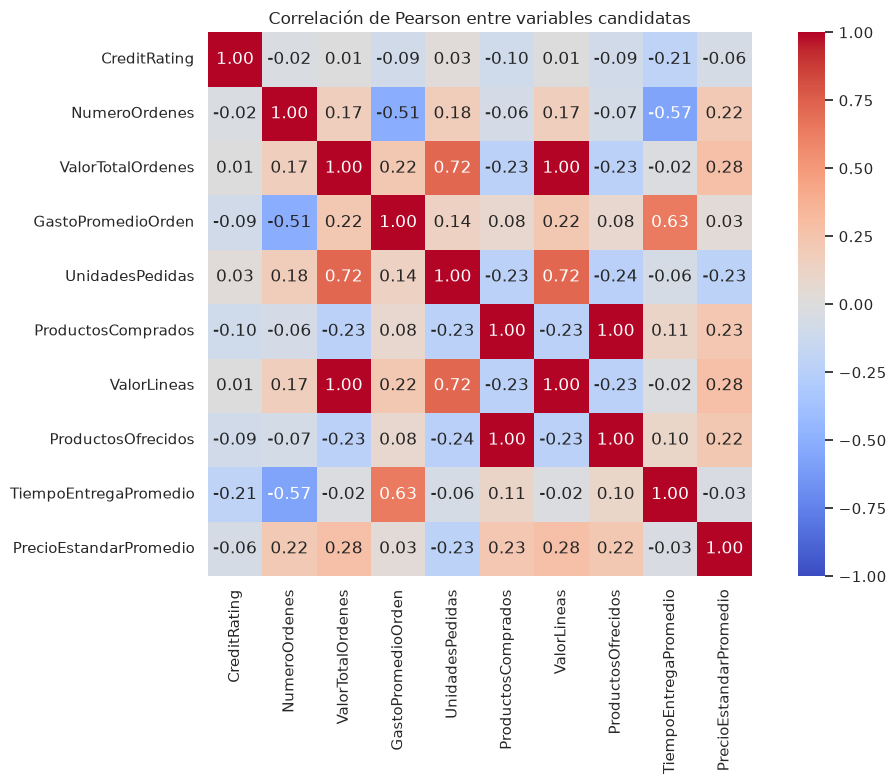

In [14]:
CANDIDATAS = ["CreditRating", *NUMERICAS]
corr = datos[CANDIDATAS].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlación de Pearson entre variables candidatas"); plt.tight_layout(); plt.show()

### 4.2 Validación de los supuestos de la selección
Cada afirmación del EDA que sustenta una decisión se comprueba con los datos actuales.

In [15]:
def r(a, b): return datos[a].corr(datos[b])

gasto_calc = datos["ValorTotalOrdenes"] / datos["NumeroOrdenes"]
r_s = datos["NumeroOrdenes"].corr(datos["ValorTotalOrdenes"], method="spearman")

verificaciones = [
    ("ValorLineas es redundante con ValorTotalOrdenes (r > 0.95)",
     r("ValorTotalOrdenes", "ValorLineas") > 0.95, f"r = {r('ValorTotalOrdenes', 'ValorLineas'):.3f}"),
    ("ProductosOfrecidos es redundante con ProductosComprados (r > 0.95)",
     r("ProductosComprados", "ProductosOfrecidos") > 0.95, f"r = {r('ProductosComprados', 'ProductosOfrecidos'):.3f}"),
    ("NumeroOrdenes y ValorTotalOrdenes aportan información distinta (|r| < 0.3)",
     abs(r("NumeroOrdenes", "ValorTotalOrdenes")) < 0.3,
     f"Pearson = {r('NumeroOrdenes', 'ValorTotalOrdenes'):.3f} | Spearman = {r_s:.3f}"),
    ("GastoPromedioOrden = ValorTotalOrdenes / NumeroOrdenes (variable derivada)",
     np.allclose(datos["GastoPromedioOrden"], gasto_calc, rtol=1e-6), "comparación exacta fila a fila"),
]
for texto, ok, detalle in verificaciones:
    print(("✔" if ok else "✘"), texto, "→", detalle)

✔ ValorLineas es redundante con ValorTotalOrdenes (r > 0.95) → r = 1.000
✔ ProductosOfrecidos es redundante con ProductosComprados (r > 0.95) → r = 0.999
✔ NumeroOrdenes y ValorTotalOrdenes aportan información distinta (|r| < 0.3) → Pearson = 0.168 | Spearman = 0.159
✔ GastoPromedioOrden = ValorTotalOrdenes / NumeroOrdenes (variable derivada) → comparación exacta fila a fila


### 4.3 Decisión por variable

In [16]:
DECISION = {
    "ValorTotalOrdenes":     ("Seleccionada", "Tamaño del proveedor en monto comprado. Variable principal del sprint. Muy asimétrica: requiere transformación (sección 5)."),
    "NumeroOrdenes":         ("Seleccionada", "Actividad del proveedor (frecuencia de compra). Correlación baja con el monto, por lo que aporta información distinta. Ver limitación en 4.4."),
    "ValorLineas":           ("Descartada", "Redundante con ValorTotalOrdenes (r ≈ 1)."),
    "GastoPromedioOrden":    ("Descartada", "Derivada de las dos variables seleccionadas (monto / órdenes); incluirla las duplicaría."),
    "UnidadesPedidas":       ("Descartada", "Mide el tamaño por volumen y se relaciona fuertemente con el monto; duplicaría el peso del tamaño."),
    "ProductosComprados":    ("Descartada", "Fuera del alcance del sprint (monto y órdenes) y casi idéntica a ProductosOfrecidos."),
    "ProductosOfrecidos":    ("Descartada", "Redundante con ProductosComprados (r ≈ 1) y proviene del catálogo, no de las compras."),
    "TiempoEntregaPromedio": ("Descartada", "Atributo logístico del catálogo; fuera del alcance del sprint."),
    "PrecioEstandarPromedio":("Descartada", "Atributo del catálogo de productos, no del comportamiento de compra."),
    "CreditRating":          ("Descartada", "Variable ordinal discreta con muy pocos valores; poco adecuada para distancias euclidianas."),
}

filas = []
for v in CANDIDATAS:
    otras = corr[v].drop(v).abs()
    filas.append({
        "Variable": v,
        "Nulos": datos[v].isna().sum(),
        "CV (%)": datos[v].std() / datos[v].mean() * 100,
        "Asimetría": datos[v].skew(),
        "Máx |r| con otra": otras.max(),
        "Con cuál": otras.idxmax(),
        "Decisión": DECISION[v][0],
        "Justificación": DECISION[v][1],
    })
tabla_seleccion = (pd.DataFrame(filas)
                   .sort_values("Decisión", ascending=False, kind="stable")
                   .reset_index(drop=True))
tabla_seleccion

,Variable,Nulos,CV (%),Asimetría,Máx |r| con otra,Con cuál,Decisión,Justificación
0,NumeroOrdenes,0,32.66,-2.67,0.57,TiempoEntregaPromedio,Seleccionada,"Actividad del proveedor (frecuencia de compra). Correlación baja con el monto, por lo que aporta información distinta. Ver limitación en 4.4."
1,ValorTotalOrdenes,0,133.74,1.43,1.00,ValorLineas,Seleccionada,Tamaño del proveedor en monto comprado. Variable principal del sprint. Muy asimétrica: requiere transformación (sección 5).
2,CreditRating,0,58.32,2.25,0.21,TiempoEntregaPromedio,Descartada,Variable ordinal discreta con muy pocos valores; poco adecuada para distancias euclidianas.
3,GastoPromedioOrden,0,268.61,5.35,0.63,TiempoEntregaPromedio,Descartada,Derivada de las dos variables seleccionadas (monto / órdenes); incluirla las duplicaría.
4,UnidadesPedidas,0,113.88,1.05,0.72,ValorLineas,Descartada,Mide el tamaño por volumen y se relaciona fuertemente con el monto; duplicaría el peso del tamaño.
5,ProductosComprados,0,122.59,1.86,1.00,ProductosOfrecidos,Descartada,Fuera del alcance del sprint (monto y órdenes) y casi idéntica a ProductosOfrecidos.
6,ValorLineas,0,133.74,1.43,1.00,ValorTotalOrdenes,Descartada,Redundante con ValorTotalOrdenes (r ≈ 1).
7,ProductosOfrecidos,0,121.80,1.86,1.00,ProductosComprados,Descartada,"Redundante con ProductosComprados (r ≈ 1) y proviene del catálogo, no de las compras."
8,TiempoEntregaPromedio,0,37.46,3.20,0.63,GastoPromedioOrden,Descartada,Atributo logístico del catálogo; fuera del alcance del sprint.
9,PrecioEstandarPromedio,0,53.03,-0.05,0.28,ValorTotalOrdenes,Descartada,"Atributo del catálogo de productos, no del comportamiento de compra."


In [17]:
VARIABLES_CLUSTERING = [v for v, (d, _) in DECISION.items() if d == "Seleccionada"]
print("Variables del clustering:", VARIABLES_CLUSTERING)

Variables del clustering: ['ValorTotalOrdenes', 'NumeroOrdenes']


### 4.4 Limitaciones de la selección

In [18]:
print("1. Concentración de NumeroOrdenes: "
      f"el {pct_moda:.1f} % de los proveedores tiene exactamente {moda:.0f} órdenes y el {pct_iqr:.1f} % está en [{q1:.0f}, {q3:.0f}].")
print("   Por eso la separación entre grupos estará dominada por el monto; los proveedores con muy pocas órdenes")
print(f"   ({len(atipicos)} atípicos) son los que más pesan en esa dimensión después del escalado.")
print()
print("2. Dos variables dan un clustering fácil de interpretar y graficar, pero describen solo tamaño y actividad;")
print("   no capturan precio, calidad ni tiempos de entrega.")
print()
print("3. El monto incluye órdenes pendientes y rechazadas (el consolidado no filtra por Status).")
print("   Es una decisión abierta del equipo que podría modificar ValorTotalOrdenes de algunos proveedores.")

1. Concentración de NumeroOrdenes: el 55.7 % de los proveedores tiene exactamente 51 órdenes y el 88.6 % está en [50, 51].
   Por eso la separación entre grupos estará dominada por el monto; los proveedores con muy pocas órdenes
   (10 atípicos) son los que más pesan en esa dimensión después del escalado.

2. Dos variables dan un clustering fácil de interpretar y graficar, pero describen solo tamaño y actividad;
   no capturan precio, calidad ni tiempos de entrega.

3. El monto incluye órdenes pendientes y rechazadas (el consolidado no filtra por Status).
   Es una decisión abierta del equipo que podría modificar ValorTotalOrdenes de algunos proveedores.


## 5. Task 3.1.4 – Datos finales y `StandardScaler`

Pasos:
1. Construir el dataset final con las variables seleccionadas y validar su calidad.
2. Decidir y aplicar la transformación logarítmica según la evidencia de la sección 3.4.
3. Aplicar `StandardScaler` (media 0 y desviación estándar 1) sobre las variables del modelo.
4. Verificar el resultado y guardar los archivos.

`StandardScaler` es necesario porque K-Means usa distancias: sin escalar, el monto (cientos de miles) dominaría sobre el número de órdenes (decenas).

In [19]:
SELECCION = VARIABLES_CLUSTERING

final = datos[["VendorID", "NombreProveedor", *SELECCION]].copy()

# Validaciones del dataset final
assert final["VendorID"].is_unique, "VendorID duplicado"
assert final[SELECCION].notna().all().all(), "Hay nulos en las variables seleccionadas"
assert (final[SELECCION] >= 0).all().all(), "Hay valores negativos"

print(f"Dataset final: {final.shape[0]} proveedores × {len(SELECCION)} variables del modelo")
print("Nulos:", int(final[SELECCION].isna().sum().sum()), "| VendorID únicos:", final['VendorID'].is_unique)
final[SELECCION].describe().T

Dataset final: 88 proveedores × 2 variables del modelo
Nulos: 0 | VendorID únicos: True


,count,mean,std,min,25%,50%,75%,max
ValorTotalOrdenes,88.00,"800,982.18","1,071,243.46",17.00,"25,603.70","102,009.78","1,491,743.72","5,034,266.74"
NumeroOrdenes,88.00,45.67,14.91,1.00,50.00,51.00,51.00,54.00


### 5.1 Transformación logarítmica

Se transforma con `log1p` solo la variable cuya asimetría **mejora** con la transformación y que es fuertemente asimétrica a la derecha. `log1p` en lugar de `log` evita problemas si algún valor fuera cero.

In [20]:
evidencia = pd.DataFrame({
    "Asimetría original": final[SELECCION].skew(),
    "Asimetría con log1p": np.log1p(final[SELECCION]).skew(),
})
display(evidencia)

# Regla explícita: transformar si la asimetría es > 1 y el log la reduce
TRANSFORMAR_LOG = [v for v in SELECCION
                   if evidencia.loc[v, "Asimetría original"] > 1
                   and abs(evidencia.loc[v, "Asimetría con log1p"]) < abs(evidencia.loc[v, "Asimetría original"])]
print("Variables con transformación logarítmica:", TRANSFORMAR_LOG)

,Asimetría original,Asimetría con log1p
ValorTotalOrdenes,1.43,-0.69
NumeroOrdenes,-2.67,-2.73


Variables con transformación logarítmica: ['ValorTotalOrdenes']


### 5.2 Escalado con `StandardScaler`

In [21]:
for v in TRANSFORMAR_LOG:
    final[f"{v}_log"] = np.log1p(final[v])

cols_modelo = [f"{v}_log" if v in TRANSFORMAR_LOG else v for v in SELECCION]
cols_z = [f"{v}_z" for v in SELECCION]

scaler = StandardScaler()
final[cols_z] = scaler.fit_transform(final[cols_modelo])

# Verificación: media 0 y desviación estándar 1 (StandardScaler usa ddof=0)
print("Media de las variables escaladas:", final[cols_z].mean().round(6).to_dict())
print("Desv. est. (ddof=0)             :", final[cols_z].std(ddof=0).round(6).to_dict())
assert np.allclose(final[cols_z].mean(), 0, atol=1e-9)
assert np.allclose(final[cols_z].std(ddof=0), 1, atol=1e-9)

# Reversibilidad: se puede volver a la escala original del modelo
assert np.allclose(scaler.inverse_transform(final[cols_z]), final[cols_modelo])

params = pd.DataFrame({"Variable usada": cols_modelo, "Media": scaler.mean_, "Escala (desv. est.)": scaler.scale_})
params

Media de las variables escaladas: {'ValorTotalOrdenes_z': -0.0, 'NumeroOrdenes_z': -0.0}
Desv. est. (ddof=0)             : {'ValorTotalOrdenes_z': 1.0, 'NumeroOrdenes_z': 1.0}


,Variable usada,Media,Escala (desv. est.)
0,ValorTotalOrdenes_log,11.80,2.53
1,NumeroOrdenes,45.67,14.83


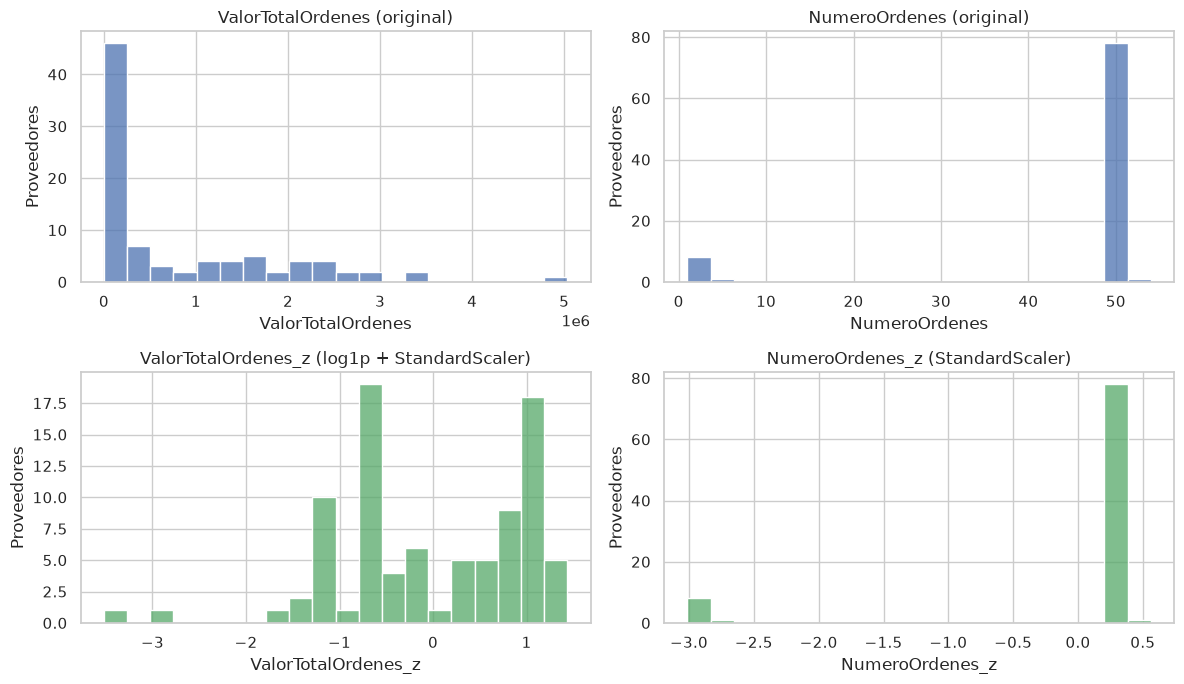

In [22]:
fig, axes = plt.subplots(2, len(SELECCION), figsize=(6 * len(SELECCION), 7))
for j, v in enumerate(SELECCION):
    sns.histplot(final[v], bins=20, ax=axes[0, j], color="#4C72B0")
    axes[0, j].set_title(f"{v} (original)")
    sns.histplot(final[f"{v}_z"], bins=20, ax=axes[1, j], color="#55A868")
    etiqueta = "log1p + StandardScaler" if v in TRANSFORMAR_LOG else "StandardScaler"
    axes[1, j].set_title(f"{v}_z ({etiqueta})")
    for ax in axes[:, j]: ax.set_ylabel("Proveedores")
plt.tight_layout(); plt.show()

### 5.3 Guardar los datos finales

In [23]:
PROC.mkdir(parents=True, exist_ok=True)
ruta_csv = PROC / "purchasing_clustering_final.csv"
ruta_scaler = PROC / "scaler_clustering.joblib"

final.to_csv(ruta_csv, index=False, encoding="utf-8-sig")
joblib.dump({"scaler": scaler, "columnas_modelo": cols_modelo, "transformar_log": TRANSFORMAR_LOG}, ruta_scaler)

print(f"Guardado: {ruta_csv}  ({final.shape[0]} filas × {final.shape[1]} columnas)")
print(f"Guardado: {ruta_scaler}")
print("\nColumnas:", list(final.columns))
final.head()

Guardado: ../data/processed/purchasing_clustering_final.csv  (88 filas × 7 columnas)
Guardado: ../data/processed/scaler_clustering.joblib

Columnas: ['VendorID', 'NombreProveedor', 'ValorTotalOrdenes', 'NumeroOrdenes', 'ValorTotalOrdenes_log', 'ValorTotalOrdenes_z', 'NumeroOrdenes_z']


,VendorID,NombreProveedor,ValorTotalOrdenes,NumeroOrdenes,ValorTotalOrdenes_log,ValorTotalOrdenes_z,NumeroOrdenes_z
0,1492,Australia Bike Retailer,"32,058.99",54.00,10.38,-0.56,0.56
1,1494,Allenson Cycles,"498,589.59",51.00,13.12,0.52,0.36
2,1496,Advanced Bicycles,"28,502.09",51.00,10.26,-0.61,0.36
3,1498,"Trikes, Inc.","1,461,653.95",50.00,14.20,0.95,0.29
4,1500,Morgan Bike Accessories,"23,146.99",50.00,10.05,-0.69,0.29


**Uso en el modelado (Molina):** la matriz de entrada de K-Means son las columnas `*_z` de `purchasing_clustering_final.csv`. Para interpretar los centroides en unidades originales, cargar `scaler_clustering.joblib` y usar `inverse_transform` (y `np.expm1` en las variables transformadas con log).

**Recordatorio:** `data/processed/` está excluida de Git. Cada integrante genera estos archivos ejecutando este notebook.

**Decisiones abiertas del equipo (no modificadas aquí):**
- Tratamiento de órdenes pendientes (Status = 1) y rechazadas (Status = 3) en el monto.
- Tratamiento de la orden 6013 (`TotalDue` = 0).